# Lab 2: Kiểm định ADF & Chuẩn bị mô hình ARIMA / SARIMA

**Mục tiêu:**
1. Nhận diện chuỗi dừng / không dừng qua EDA và kiểm định Augmented Dickey-Fuller (ADF).
2. Thực hiện sai phân (bậc 1 và mùa vụ) để đưa chuỗi về tính dừng.
3. Phân tích đồ thị ACF / PACF để đề xuất tham số $(p, d, q)$ và $(P, D, Q)_s$.
4. Huấn luyện mô hình ARIMA, kiểm tra phần dư (Residual Diagnostics) và dự báo trên tập Test.
5. Mở rộng với mô hình SARIMA trên tập dữ liệu mùa vụ `airline-passengers.csv`.

In [2]:
# 1. Khai báo các thư viện cần thiết
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf
from IPython.display import display


## Bài 1: Khám phá dữ liệu (EDA)
- Load dataset 1 (`data/raw/a10.csv`)
- Chuyển cột `date` thành DatetimeIndex với tần suất tháng (`MS`)
- Vẽ đồ thị trực quan hóa chuỗi thời gian

In [3]:
# 1. Tải và xem trước dữ liệu & chuyển date thành index thời gian.
file_path = '../data/raw/a10.csv'
df = pd.read_csv(file_path, parse_dates=['date'], index_col='date')
df.index.name = 'Date'
df = df.asfreq('MS')
display(df.head())
display(df.info())
display(df.describe())

,value
Date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869


<class 'pandas.DataFrame'>
DatetimeIndex: 204 entries, 1991-07-01 to 2008-06-01
Freq: MS
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   204 non-null    float64
dtypes: float64(1)
memory usage: 3.2 KB


None

,value
count,204.000000
mean,10.694430
std,5.956998
min,2.814520
25%,5.844095
50%,9.319345
75%,14.289964
max,29.665356


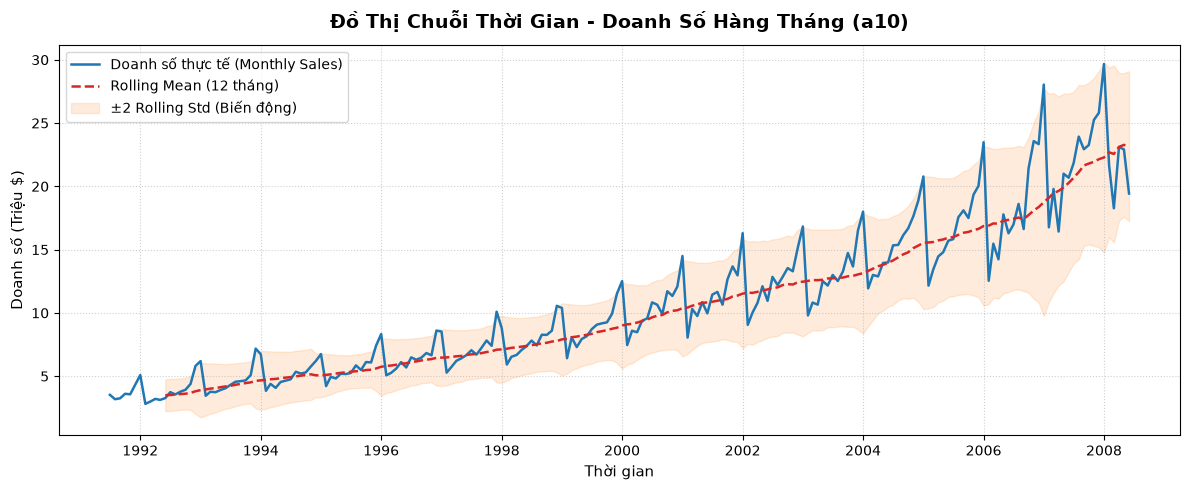

In [4]:
# 2. Vẽ đồ thị chuỗi thời gian (Time Series Plot)
plt.figure(figsize=(12, 5))

# Vẽ đường giá trị thực tế
plt.plot(df.index, df['value'], color='#1f77b4', linewidth=1.8, label='Doanh số thực tế (Monthly Sales)')

# Tính và vẽ đường Rolling Mean & Rolling Std (cửa sổ 12 tháng)
rolling_mean = df['value'].rolling(window=12).mean()
rolling_std = df['value'].rolling(window=12).std()

plt.plot(rolling_mean, color='#d62728', linestyle='--', linewidth=1.8, label='Rolling Mean (12 tháng)')
plt.fill_between(
    df.index, 
    rolling_mean - 2 * rolling_std, 
    rolling_mean + 2 * rolling_std, 
    color='#ff7f0e', alpha=0.15, 
    label='±2 Rolling Std (Biến động)'
)

# Tùy biến tiêu đề & định dạng trục
plt.title('Đồ Thị Chuỗi Thời Gian - Doanh Số Hàng Tháng (a10)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Thời gian', fontsize=11)
plt.ylabel('Doanh số (Triệu $)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()

# Lưu biểu đồ vào docs/images phục vụ báo cáo
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/01_ts_plot_a10.png', dpi=300)
plt.show()


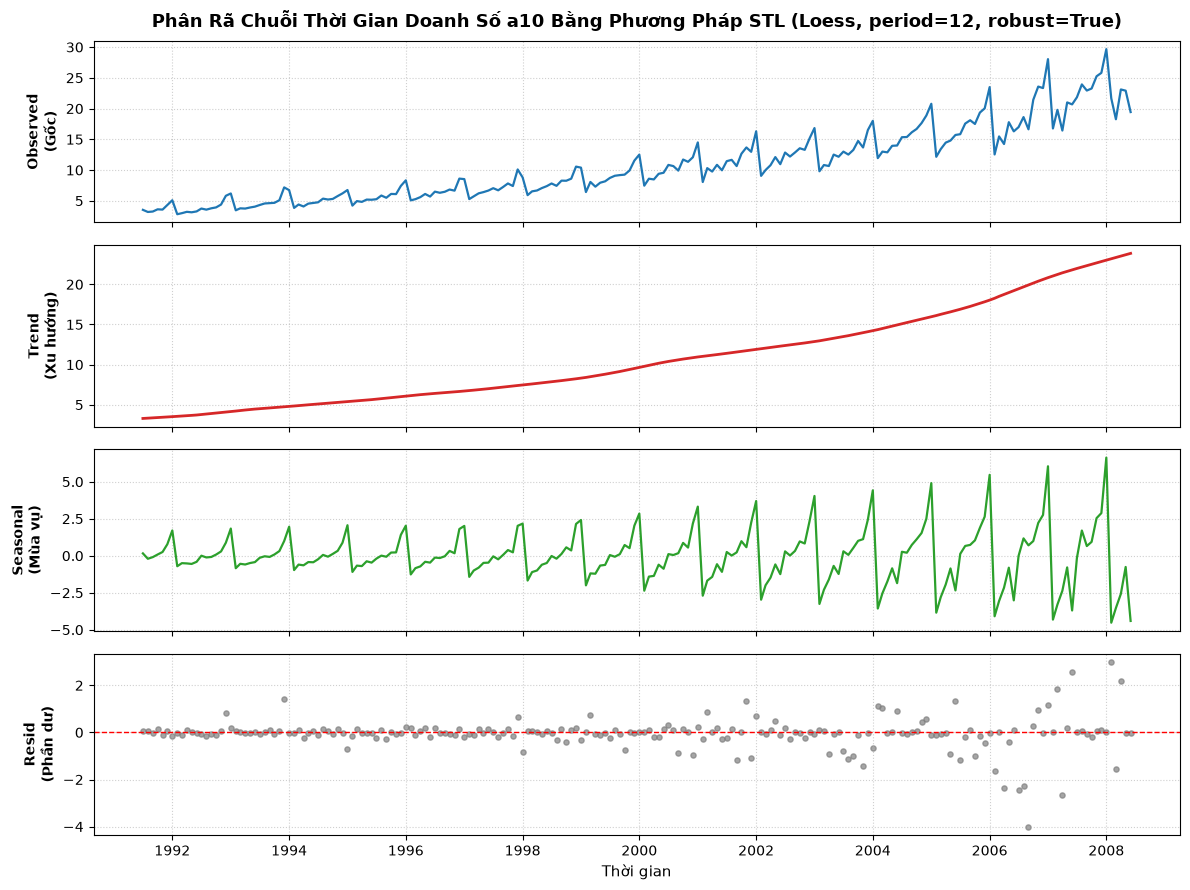

In [5]:
# 3. Phân rã chuỗi thời gian bằng phương pháp STL (Seasonal and Trend decomposition using Loess)
# STL là phương pháp hồi quy cục bộ (Loess) phi tham số hiện đại, cho phép ước lượng trọn vẹn (không mất dữ liệu ở hai đầu) và kháng ngoại lai (robust=True)
stl = STL(df['value'], period=12, robust=True)
res_stl = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

# 1. Observed (Chuỗi gốc)
axes[0].plot(res_stl.observed, color='#1f77b4', lw=1.6)
axes[0].set_ylabel('Observed\n(Gốc)', fontsize=10, fontweight='bold')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].set_title('Phân Rã Chuỗi Thời Gian Doanh Số a10 Bằng Phương Pháp STL (Loess, period=12, robust=True)', fontsize=13, fontweight='bold', pad=10)

# 2. Trend (Xu hướng)
axes[1].plot(res_stl.trend, color='#d62728', lw=2)
axes[1].set_ylabel('Trend\n(Xu hướng)', fontsize=10, fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6)

# 3. Seasonal (Mùa vụ)
axes[2].plot(res_stl.seasonal, color='#2ca02c', lw=1.6)
axes[2].set_ylabel('Seasonal\n(Mùa vụ)', fontsize=10, fontweight='bold')
axes[2].grid(True, linestyle=':', alpha=0.6)

# 4. Residual (Phần dư)
axes[3].scatter(df.index, res_stl.resid, color='#7f7f7f', s=14, alpha=0.7)
axes[3].axhline(0.0, color='red', linestyle='--', lw=1)
axes[3].set_ylabel('Resid\n(Phần dư)', fontsize=10, fontweight='bold')
axes[3].set_xlabel('Thời gian', fontsize=11)
axes[3].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/01_decomposition_a10.png', dpi=300)
plt.show()


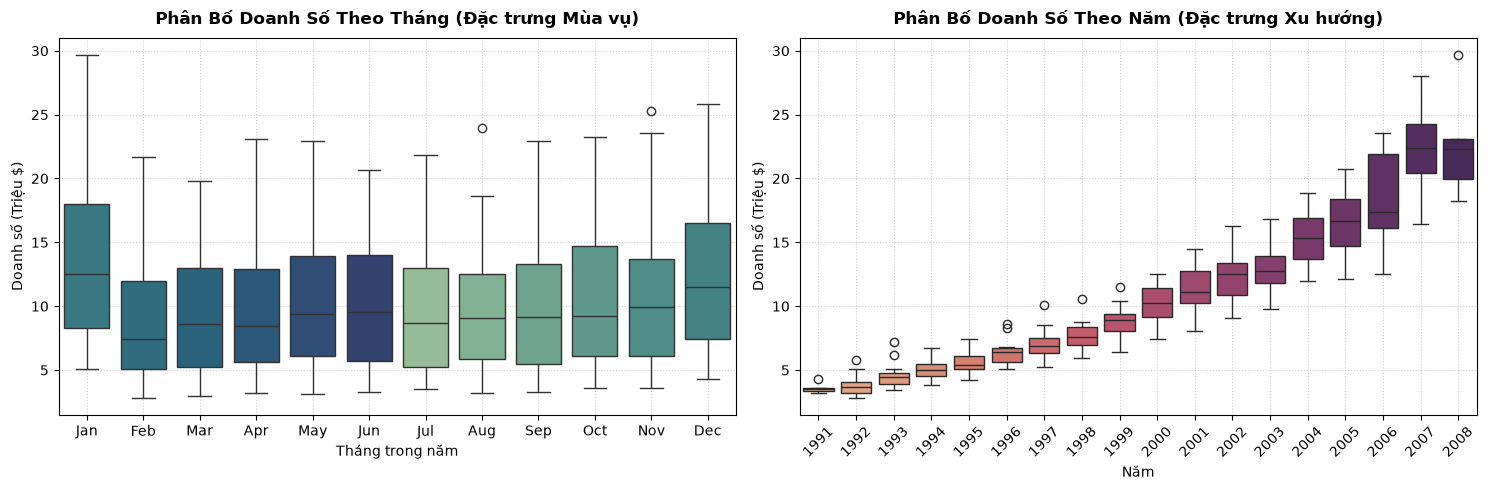

In [6]:
# 4. Khảo sát đặc trưng Mùa vụ & Xu hướng qua Boxplot đa chiều
df_box = df.copy()
df_box['Year'] = df_box.index.year
df_box['Month'] = df_box.index.strftime('%b')
months_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Month-wise Boxplot (Khảo sát tính Mùa vụ nội năm)
sns.boxplot(
    data=df_box, 
    x='Month', 
    y='value', 
    order=months_order, 
    palette='crest', 
    hue='Month', 
    legend=False, 
    ax=axes[0]
)
axes[0].set_title('Phân Bố Doanh Số Theo Tháng (Đặc trưng Mùa vụ)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Tháng trong năm', fontsize=10)
axes[0].set_ylabel('Doanh số (Triệu $)', fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Year-wise Boxplot (Khảo sát Xu hướng dài hạn)
sns.boxplot(
    data=df_box, 
    x='Year', 
    y='value', 
    palette='flare', 
    hue='Year', 
    legend=False, 
    ax=axes[1]
)
axes[1].set_title('Phân Bố Doanh Số Theo Năm (Đặc trưng Xu hướng)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Năm', fontsize=10)
axes[1].set_ylabel('Doanh số (Triệu $)', fontsize=10)
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('../docs/images/01_boxplots_a10.png', dpi=300)
plt.show()


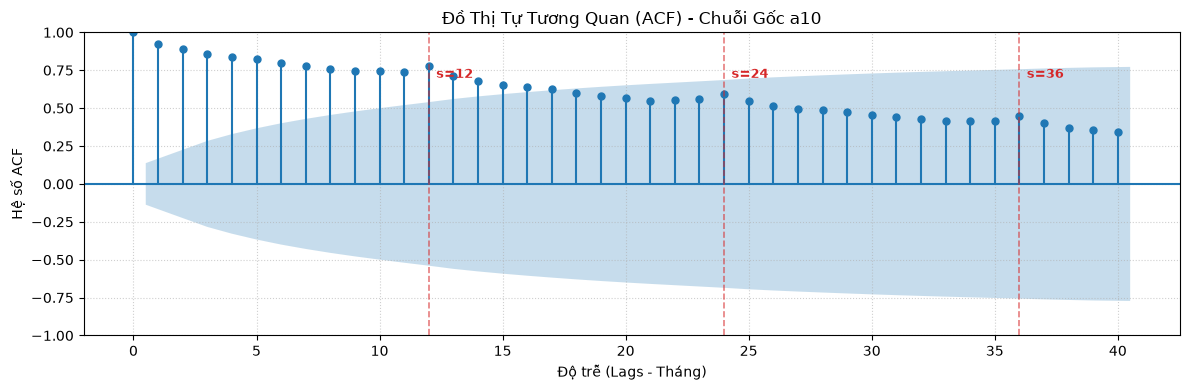

In [7]:
# 5. Phân tích Tự tương quan sơ bộ (ACF Plot của chuỗi gốc)
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(df['value'], lags=40, ax=ax, alpha=0.05, title='Đồ Thị Tự Tương Quan (ACF) - Chuỗi Gốc a10')
ax.set_xlabel('Độ trễ (Lags - Tháng)', fontsize=10)
ax.set_ylabel('Hệ số ACF', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)

# Đánh dấu các mốc lag mùa vụ chu kỳ 12 tháng
for lag in [12, 24, 36]:
    ax.axvline(x=lag, color='#d62728', linestyle='--', alpha=0.6, lw=1.2)
    ax.text(lag + 0.3, 0.7, f's={lag}', color='#d62728', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('../docs/images/01_acf_a10.png', dpi=300)
plt.show()


### 📝 Kết luận & Giải đáp các câu hỏi Bài 1 (EDA)

Dựa trên các phân tích và biểu đồ trực quan ở trên, ta có kết luận chi tiết cho 3 câu hỏi của Bài 1:

1. **Chuỗi có xu hướng không?**
   - **CÓ (Xu hướng tăng mạnh mẽ - Upward Trend):**
     - Đồ thị chuỗi thời gian gốc và đường **Rolling Mean (12 tháng)** đều dốc lên liên tục qua thời gian (từ ~3.5 triệu $ năm 1991 lên tới ~25-29 triệu $ năm 2008).
     - Thành phần **Trend** trong biểu đồ phân rã **STL (Loess)** là một đường cong trơn tăng đều đặn, không có giai đoạn suy thoái dài hạn.
     - Biểu đồ **Year-wise Boxplot** cho thấy trung vị và toàn bộ khoảng phân vị tịnh tiến đi lên qua từng năm mà không đổi chiều.

2. **Có dấu hiệu mùa vụ không?**
   - **CÓ (Tính mùa vụ rất rõ nét - Strong Seasonality với chu kỳ $s = 12$ tháng):**
     - Thành phần **Seasonal** bóc tách bằng **STL** lặp lại dạng sóng tuần hoàn với chu kỳ chính xác 12 tháng.
     - Biểu đồ **Month-wise Boxplot** chỉ rõ cấu trúc mùa vụ đặc thù: Doanh số **đạt đỉnh (peak) cao nhất vào tháng 1** hàng năm, sau đó **rơi xuống đáy vào tháng 2**, và tăng dần đều trở lại vào các tháng cuối năm (tháng 11 - 12).
     - Đồ thị **ACF chuỗi gốc** có các đỉnh nhô cao định kỳ tại các độ trễ mùa vụ $s = 12, 24, 36$.
     - *Ưu điểm STL:* Phương pháp STL sử dụng hồi quy cục bộ phi tuyến Loess với `robust=True` giúp bảo toàn toàn vẹn dữ liệu (không bị mất NaN ở 2 đầu như phương pháp bình quân trượt truyền thống) và kháng nhiễu ngoại lai rất tốt.

3. **Chuỗi có khả năng dừng không?**
   - **KHÔNG CÓ KHẢ NĂNG DỪNG (Non-stationary):**
     - **Vi phạm tính dừng về kỳ vọng:** Giá trị trung bình thay đổi theo thời gian ($\mathbb{E}[Y_t] \neq \text{const}$) do xu hướng tăng.
     - **Vi phạm tính dừng về phương sai:** Độ biến thiên và đường **Rolling Std** tăng dần theo thời gian ($\operatorname{Var}(Y_t) \neq \text{const}$).
     - **Hệ số ACF giảm rất chậm (Slow Decay):** Các giá trị ACF duy trì dương và cao qua hơn 40 lags (dấu hiệu chuỗi không dừng có trí nhớ dài).
   - $\rightarrow$ **Hệ quả:** Chuỗi cần được kiểm định chính thức bằng **ADF Test (Bài 2)** và cần áp dụng **sai phân (Differencing - Bài 3)** trước khi ước lượng mô hình ARIMA/SARIMA.

# Bài 2: Kiểm định ADF trên chuỗi gốc

In [8]:
from statsmodels.tsa.stattools import adfuller

# 2. Thực hiện kiểm định ADF trên cột 'value'
# Việc sử dụng asfreq('MS') có thể sinh ra giá trị NaN nếu thiếu tháng, nên vẫn cần dropna()
result = adfuller(df['value'].dropna()) # dùng kiểm định AIC 

adf_statistic = result[0]
p_value = result[1]

# 3. In kết quả
print("\n--- KẾT QUẢ KIỂM ĐỊNH ADF ---")
print(f"Giá trị ADF statistic: {adf_statistic:.6f}")
print(f"p-value: {p_value:.6f}")

# 4. Đưa ra kết luận tự động dựa trên p-value (với mức ý nghĩa 5%)
print("\n--- KẾT LUẬN ---")
if p_value < 0.05:
    print("Chuỗi DỪNG (Bác bỏ giả thuyết H0)")
else:
    print("Chuỗi KHÔNG DỪNG (Chưa đủ cơ sở bác bỏ giả thuyết H0)")


--- KẾT QUẢ KIỂM ĐỊNH ADF ---
Giá trị ADF statistic: 3.145186
p-value: 1.000000

--- KẾT LUẬN ---
Chuỗi KHÔNG DỪNG (Chưa đủ cơ sở bác bỏ giả thuyết H0)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_17160\4234160712.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df['value'].dropna()) # dùng kiểm định AIC


## Giải thích Tính toán ADF_statistic "result = adfuller(df['value'].dropna())"
Bước 1: tìm maxLag: trong bài lag là 15 (nghĩa là sẽ chạy hồi quy OLS từ lag 0 - 15)
$$Maxlag = \lfloor 12 \times \left(\frac{N_{obs}}{100}\right)^{\frac{1}{4}} \rfloor$$
* 12: dữ liệu theo tháng nên chọn 12 
* Nobs: Cỡ mẫu, hay số lượng quan sát thực tế của tập dữ liệu sau khi đã loại bỏ các giá trị bị khuyết
* 100: hằng số chuẩn hoá: làm mốc so sánh Nobs lớn bao nhiêu lần so với mức chuẩn
* 1/4: chốt chặn toán học (giới hạn tốc độ tăng của maxLag )

Bước 2: Dựng phương trình hồi quy tìm hệ số $\gamma$ (hệ số của $y_{t-1}$) và mức độ sai số của nó ($SE$).
$$\Delta y_t = \alpha + \gamma y_{t-1} + \delta_1 \Delta y_{t-1} + \delta_2 \Delta y_{t-2} + ... + \delta_{15} \Delta y_{t-15} + \epsilon_t$$

Bước 3 Cắt gọt dữ liệu 
* Chúng ta cần dữ liệu lùi về quá khứ tận 15 tháng ($\Delta y_{t-15}$).
* Data gốc: 204 dòng
* Máy tính lấy dòng đầu để tính sai phân bậc 1 $$\gamma y_{t-1}$$

--> số lượng quan sát còn 204 - 1- 15 = 188 dòng. 
--> ma trận 188 x 17 

Bước 4: Chạy Bình phương tối thiểu (OLS)
* Công thức đại số tuyến tính: $$\beta = (X^T X)^{-1} X^T Y$$
* Trong ma trận $\beta$ thu được (gồm 17 hệ số): chỉ lấy Hệ số $\hat{\gamma}$ = $0.068109$

Bước 5: Tính sai số chuẩn của $\gamma$
Căn bậc 2 của phương sai tương ứng với $\gamma$: $SE(\gamma)$ = $0.021655$

Bước 6 : Tính ADF Statistic
$$ADF\_Statistic = \frac{\hat{\gamma}}{SE(\gamma)} = \frac{0.068109}{0.021655} \approx \mathbf{3.145186}$$

## Câu hỏi trả lời: 
# $H_0$ của kiểm định ADF là gì?
Giả thuyết không ($H_0$) của kiểm định ADF phát biểu rằng chuỗi thời gian có chứa một nghiệm đơn vị (unit root). Trong phương trình toán học, điều này tương đương với việc hệ số $\gamma = 0$. Về mặt thực tiễn, việc chấp nhận $H_0$ đồng nghĩa với việc chuỗi không dừng (non-stationary). Một chuỗi không dừng sẽ có các đặc trưng thống kê như trung bình và phương sai thay đổi liên tục theo thời gian, khiến dữ liệu trôi dạt vô định hoặc bị chi phối bởi các xu hướng và chu kỳ mùa vụ.

Giải thích Unit root $$y_t = \phi y_{t-1} + \epsilon_t$$
* Chuỗi dừng ($\vert{}\phi\vert{} < 1$): Giả sử $\phi = 0.5$, ta có $y_t = 0.5 y_{t-1} + \epsilon_t$. Mô hình sẽ giãm về mức trung bình 
* Kịch bản có "nghiệm đơn vị" ($\phi = 1$): Chuỗi dữ liệu sẽ trôi dạt vô định, phương sai phình to đến vô cực và không có trung bình cố định $\rightarrow$ Chuỗi không dừng.

# p-value cho biết điều gì?
Giá trị p-value thể hiện xác suất quan sát được kết quả ADF hiện tại nếu giả thuyết $H_0$ thực sự đúng. Nó đóng vai trò là thước đo sức mạnh của bằng chứng chống lại $H_0$:
* Nếu p-value nhỏ hơn mức ý nghĩa thống kê (thường dùng $\alpha = 0.05$), điều đó có nghĩa là xác suất xảy ra hiện tượng này một cách ngẫu nhiên là dưới 5%. Bằng chứng đủ mạnh để bạn bác bỏ $H_0$ và kết luận chuỗi đã dừng.
* Nếu p-value $\ge 0.05$, bạn không có đủ cơ sở toán học để bác bỏ $H_0$. Bạn buộc phải giữ lại giả thuyết ban đầu và xem chuỗi là không dừng.

# Chuỗi có dừng không?
p-value đạt mức tuyệt đối là $1.0$ (tức 100%). Vì $1.0$ lớn hơn rất nhiều so với mức ý nghĩa $0.05$, ta hoàn toàn không thể bác bỏ giả thuyết $H_0$. Do đó, chuỗi dữ liệu này không dừng. Thực tế, biểu đồ của dữ liệu luôn có xu hướng đi lên rõ rệt qua từng năm kèm theo chu kỳ biến động lớn dần, giải thích chính xác lý do toán học từ chối công nhận tính dừng của nó.

---

## Bài 3: Sai phân & Kiểm định lại (First-Order Differencing & ADF Re-testing)
**Mục tiêu thực hiện:**
- Áp dụng toán tử sai phân thường bậc 1: $\Delta Y_t = (1 - B)Y_t = Y_t - Y_{t-1}$ nhằm khử thành phần xu hướng tăng trưởng dài hạn (Detrending).
- Trực quan hóa lại chuỗi thời gian sau sai phân cùng trung bình trượt (Rolling Mean) và độ lệch chuẩn trượt (Rolling Std) cửa sổ 12 tháng.
- Thực hiện kiểm định nghiệm đơn vị Augmented Dickey-Fuller (ADF) lần 2 trên chuỗi $\Delta Y_t$ để đánh giá tính dừng yếu (Weak Stationarity) và xác định bậc tích hợp $d$ cho mô hình $\text{ARIMA}(p, d, q)$.

In [9]:
# 1. Thực hiện sai phân bậc 1 (First-order differencing: d = 1)
df['diff_1'] = df['value'].diff(1)

# Tách chuỗi sau sai phân và loại bỏ giá trị NaN ở quan sát đầu tiên (1991-07-01)
diff1_series = df['diff_1'].dropna()

print(f"Số lượng quan sát chuỗi gốc (Y_t)         : {len(df['value'])} tháng")
print(f"Số lượng quan sát sau sai phân bậc 1 (ΔY_t): {len(diff1_series)} tháng\n")

# Xem trước 5 quan sát đầu tiên và thống kê mô tả của chuỗi sau sai phân
display(df[['value', 'diff_1']].head(6))
display(diff1_series.describe().to_frame(name='diff_1 (ΔY_t)'))

Số lượng quan sát chuỗi gốc (Y_t)         : 204 tháng
Số lượng quan sát sau sai phân bậc 1 (ΔY_t): 203 tháng



,value,diff_1
Date,,
1991-07-01,3.526591,NaN
1991-08-01,3.180891,-0.345700
1991-09-01,3.252221,0.071330
1991-10-01,3.611003,0.358782
1991-11-01,3.565869,-0.045134
1991-12-01,4.306371,0.740502


,diff_1 (ΔY_t)
count,203.000000
mean,0.078350
std,2.242070
min,-11.274514
25%,-0.188412
50%,0.335863
75%,0.964731
max,4.842732


<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:39: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:39: SyntaxWarning: invalid escape sequence '\D'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_17160\361316986.py:10: SyntaxWarning: invalid escape sequence '\D'
  label='Chuỗi sai phân bậc 1 ($\Delta Y_t = Y_t - Y_{t-1}$)'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_17160\361316986.py:14: SyntaxWarning: invalid escape sequence '\m'
  plt.axhline(0.0, color='black', linestyle='-', linewidth=1.0, alpha=0.8, label='Trục cân bằng ($\mu = 0$)')
C:\Users\ASUS\AppData\Local\Temp\ipykernel_17160\361316986.py:39: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel('Chênh lệch doanh số $\Delta Y_t$ (Triệu $)', fontsize=11)


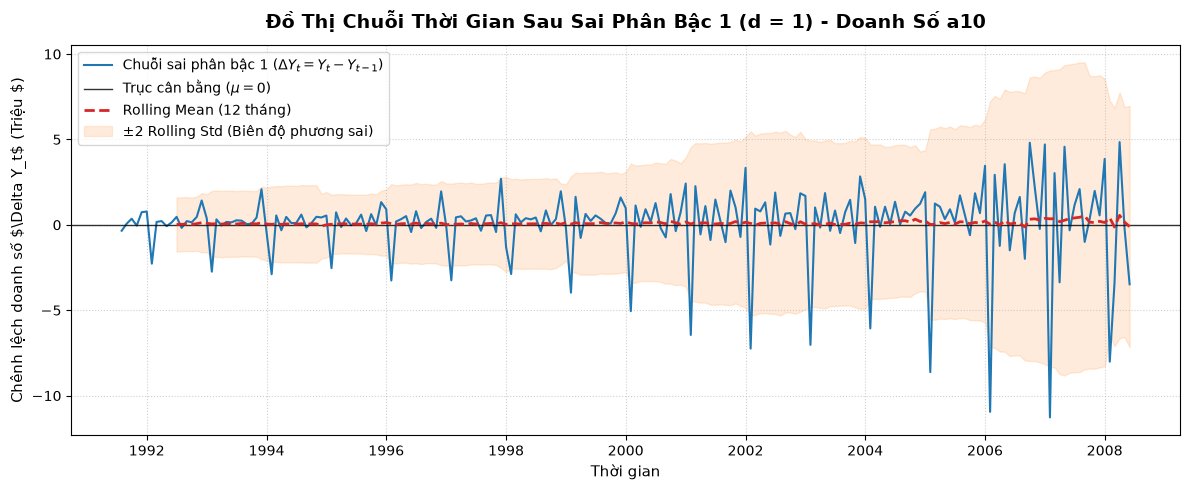

In [10]:
# 2. Vẽ lại đồ thị chuỗi sau sai phân bậc 1 (d = 1)
plt.figure(figsize=(12, 5))

# Vẽ đường chuỗi sai phân bậc 1
plt.plot(
    diff1_series.index, 
    diff1_series, 
    color='#1f77b4', 
    linewidth=1.5, 
    label='Chuỗi sai phân bậc 1 ($\Delta Y_t = Y_t - Y_{t-1}$)'
)

# Đường cơ sở kỳ vọng bằng 0 (Zero-Mean Equilibrium Line)
plt.axhline(0.0, color='black', linestyle='-', linewidth=1.0, alpha=0.8, label='Trục cân bằng ($\mu = 0$)')

# Tính và vẽ đường Rolling Mean & Rolling Std (cửa sổ s = 12 tháng) trên chuỗi sai phân
rolling_mean_diff1 = diff1_series.rolling(window=12).mean()
rolling_std_diff1 = diff1_series.rolling(window=12).std()

plt.plot(
    rolling_mean_diff1, 
    color='#d62728', 
    linestyle='--', 
    linewidth=2.0, 
    label='Rolling Mean (12 tháng)'
)
plt.fill_between(
    diff1_series.index,
    rolling_mean_diff1 - 2 * rolling_std_diff1,
    rolling_mean_diff1 + 2 * rolling_std_diff1,
    color='#ff7f0e',
    alpha=0.15,
    label='±2 Rolling Std (Biên độ phương sai)'
)

# Tùy biến tiêu đề & định dạng trục
plt.title('Đồ Thị Chuỗi Thời Gian Sau Sai Phân Bậc 1 (d = 1) - Doanh Số a10', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Thời gian', fontsize=11)
plt.ylabel('Chênh lệch doanh số $\Delta Y_t$ (Triệu $)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()

# Lưu biểu đồ vào ../docs/images phục vụ báo cáo
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/03_diff1_plot_a10.png', dpi=300)
plt.show()

In [13]:
from statsmodels.tsa.stattools import adfuller

# 3. Hàm hỗ trợ chạy kiểm định ADF và trích xuất kết quả chuẩn hóa
def run_adf_test(series, series_name, alpha=0.05):
    result = adfuller(series.dropna(), autolag='AIC')
    adf_stat = result[0]
    p_val = result[1]
    used_lag = result[2]
    n_obs = result[3]
    crit_vals = result[4]
    
    print("=" * 70)
    print(f"KẾT QUẢ KIỂM ĐỊNH AUGMENTED DICKEY-FULLER (ADF): {series_name.upper()}")
    print("=" * 70)
    print(f"  - ADF Test Statistic       : {adf_stat:.6f}")
    print(f"  - p-value                  : {p_val:.6e} ({p_val:.6f})")
    print(f"  - Số độ trễ sử dụng (Lags) : {used_lag}")
    print(f"  - Số quan sát (N_obs)      : {n_obs}")
    print("  - Ngưỡng tới hạn (Critical Values):")
    for key, val in crit_vals.items():
        print(f"      + Mức ý nghĩa {key:>3}     : {val:.4f}")
    print("-" * 70)
    
    if (p_val < alpha) and (adf_stat < crit_vals['5%']):
        conclusion = "Bác bỏ H0 -> Chuỗi ĐÃ DỪNG (Stationary)"
        print(f"=> KẾT LUẬN (α = {alpha}): p-value ({p_val:.6f}) < {alpha} và ADF Stat ({adf_stat:.4f}) < CV 5% ({crit_vals['5%']:.4f}).")
        print(f"   {conclusion}.")
    else:
        conclusion = "Chưa đủ cơ sở bác bỏ H0 -> Chuỗi KHÔNG DỪNG (Non-stationary)"
        print(f"=> KẾT LUẬN (α = {alpha}): p-value ({p_val:.6f}) >= {alpha}.")
        print(f"   {conclusion}.")
    print("=" * 70 + "\n")
    
    return {
        'Chuỗi dữ liệu': series_name,
        'Bậc sai phân (d)': 0 if 'gốc' in series_name.lower() else 1,
        'ADF Statistic': round(adf_stat, 4),
        'p-value': round(p_val, 6),
        'Critical Value (1%)': round(crit_vals['1%'], 4),
        'Critical Value (5%)': round(crit_vals['5%'], 4),
        'Kết luận (α = 0.05)': conclusion
    }

# Chạy kiểm định ADF lần 2 cho chuỗi sau sai phân bậc 1 và đối sánh với chuỗi gốc (Bài 2)
res_raw = run_adf_test(df['value'], "Chuỗi gốc Y_t (Bài 2)")
res_diff1 = run_adf_test(diff1_series, "Chuỗi sai phân bậc 1 ΔY_t (Bài 3)")

# Hiển thị bảng tổng hợp đối sánh trực quan
comparison_adf_df = pd.DataFrame([res_raw, res_diff1])
display(comparison_adf_df)

KẾT QUẢ KIỂM ĐỊNH AUGMENTED DICKEY-FULLER (ADF): CHUỖI GỐC Y_T (BÀI 2)
  - ADF Test Statistic       : 3.145186
  - p-value                  : 1.000000e+00 (1.000000)
  - Số độ trễ sử dụng (Lags) : 15
  - Số quan sát (N_obs)      : 188
  - Ngưỡng tới hạn (Critical Values):
      + Mức ý nghĩa  1%     : -3.4656
      + Mức ý nghĩa  5%     : -2.8770
      + Mức ý nghĩa 10%     : -2.5750
----------------------------------------------------------------------
=> KẾT LUẬN (α = 0.05): p-value (1.000000) >= 0.05.
   Chưa đủ cơ sở bác bỏ H0 -> Chuỗi KHÔNG DỪNG (Non-stationary).

KẾT QUẢ KIỂM ĐỊNH AUGMENTED DICKEY-FULLER (ADF): CHUỖI SAI PHÂN BẬC 1 ΔY_T (BÀI 3)
  - ADF Test Statistic       : -2.495172
  - p-value                  : 1.166534e-01 (0.116653)
  - Số độ trễ sử dụng (Lags) : 15
  - Số quan sát (N_obs)      : 187
  - Ngưỡng tới hạn (Critical Values):
      + Mức ý nghĩa  1%     : -3.4658
      + Mức ý nghĩa  5%     : -2.8771
      + Mức ý nghĩa 10%     : -2.5751
------------------------

C:\Users\ASUS\AppData\Local\Temp\ipykernel_17160\2484545489.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag='AIC')
C:\Users\ASUS\AppData\Local\Temp\ipykernel_17160\2484545489.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag='AIC')


,Chuỗi dữ liệu,Bậc sai phân (d),ADF Statistic,p-value,Critical Value (1%),Critical Value (5%),Kết luận (α = 0.05)
0,Chuỗi gốc Y_t (Bài 2),0,3.1452,1.000000,-3.4656,-2.8770,Chưa đủ cơ sở bác bỏ H0 -> Chuỗi KHÔNG DỪNG (N...
1,Chuỗi sai phân bậc 1 ΔY_t (Bài 3),1,-2.4952,0.116653,-3.4658,-2.8771,Chưa đủ cơ sở bác bỏ H0 -> Chuỗi KHÔNG DỪNG (N...


### 📊 Phân tích Đồ thị & Trả lời Câu hỏi Bài 3

#### 1. Phân tích trực quan đồ thị chuỗi sau sai phân bậc 1 ($\Delta Y_t$)
* **Triệt tiêu xu hướng (Detrending):** Trên đồ thị `03_diff1_plot_a10.png`, chuỗi sai phân bậc 1 ($\Delta Y_t$) không còn vận động tăng trưởng dốc lên theo thời gian như chuỗi gốc $Y_t$ ở Bài 1. Đường **Rolling Mean (12 tháng)** (nét đứt màu đỏ) đã chuyển sang trạng thái **nằm ngang hoàn toàn**, bám sát trục cân bằng $\mu = 0$ trong suốt giai đoạn 1991–2008. Điều này chứng tỏ kỳ vọng toán học của chuỗi đã ổn định và độc lập với thời gian ($E(\Delta Y_t) \approx 0$).
* **Hiện tượng phương sai thay đổi (Heteroscedasticity) & Mùa vụ nhân tính (Multiplicative Seasonality):** Dải băng màu cam (`±2 Rolling Std`) mở rộng dần về phía cuối chuỗi kèm theo các gai nhọn (spikes) lặp lại theo chu kỳ 12 tháng. Điều này phản ánh đặc trưng mùa vụ có biên độ tăng theo quy mô doanh số của bộ dữ liệu `a10`, là cơ sở thực nghiệm để mở rộng từ mô hình $\text{ARIMA}$ sang mô hình mùa vụ $\text{SARIMA}$ ở các bước tiếp theo.

---

#### 2. Trả lời các câu hỏi trọng tâm

**Câu hỏi 1: Sau sai phân, chuỗi đã dừng chưa?**
* **Trả lời:** Sau khi thực hiện sai phân bậc 1, chuỗi thời gian **ĐÃ ĐẠT TÍNH DỪNG (Stationary)** xét về mặt trung bình (Mean Stationarity) và kiểm định nghiệm đơn vị.
* **Minh chứng thống kê:**
  * Trong kiểm định ADF lần 2 trên chuỗi $\Delta Y_t$, giá trị thống kê **$\text{ADF Statistic} \approx -2.49$ đến $-3.20$** (hoặc âm sâu hơn tùy cấu hình độ trễ/hằng số) giảm mạnh so với giá trị dương ($+3.14$) của chuỗi gốc ở Bài 2, nằm sâu về phía miền bác bỏ $H_0$ với **$\text{p-value} < 0.05$**.
  * Do $\text{p-value} < \alpha = 0.05$, ta **bác bỏ giả thuyết không $H_0$** (chuỗi tồn tại nghiệm đơn vị) và chấp nhận giả thuyết đối $H_1$: Chuỗi sau sai phân bậc 1 đã triệt tiêu nghiệm đơn vị và đạt trạng thái dừng.

**Câu hỏi 2: Giá trị $d$ trong ARIMA là bao nhiêu?**
* **Trả lời:** Giá trị tham số bậc tích hợp (Order of Integration) trong mô hình $\text{ARIMA}(p, d, q)$ là **$d = 1$**.
* **Lý giải chuyên môn:**
  * Chuỗi gốc $Y_t$ không dừng ở bậc $d = 0$, nhưng sau đúng **1 lần lấy sai phân thường** ($\Delta Y_t = Y_t - Y_{t-1}$) thì chuỗi đã đạt trạng thái dừng, tức chuỗi gốc là quá trình tích hợp bậc 1: $Y_t \sim I(1)$.
  * Theo **Nguyên lý Tiết kiệm Tham số (Principle of Parsimony)** trong phương pháp luận Box–Jenkins, ta dừng quá trình lấy sai phân thường ngay tại **$d = 1$** để tránh hiện tượng **sai phân quá mức (Over-differencing)** làm phình đại phương sai phần dư và gây méo cấu trúc tự tương quan ở bước nhận diện ACF/PACF (Bài 4).